# Advanced Python for Battery Engineers with PyBaMM

> **Environment note:** these notebooks need a Python environment with a working
> PyBaMM install (`pip install pybamm numpy pandas scipy matplotlib ipykernel`).
> All simulations below use `pybamm.lithium_ion` models with the built-in
> `"Chen2020"` parameter set and run in well under a second each, so nothing
> here should take more than a few seconds to execute.

In [1]:
%matplotlib inline
import time
import itertools
from functools import partial, lru_cache
from contextlib import contextmanager
from dataclasses import dataclass, field

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

import pybamm

pybamm.set_logging_level("WARNING")

## 1. Object-Oriented Battery Models

PyBaMM itself is built around class hierarchies: every model (`pybamm.lithium_ion.SPM`,
`pybamm.lithium_ion.DFN`, `pybamm.equivalent_circuit.Thevenin`, ...) is a subclass of
`pybamm.BaseModel`, and equivalent circuit models are literally *composed* of smaller
circuit-element submodels. This section builds the same kind of design — validated
properties, inheritance/polymorphism, and dataclasses — on small battery-engineering
examples, then connects a dataclass directly to a real `pybamm.ParameterValues` update.

### Example 1: A `Cell` class with validated properties

A plain attribute lets you assign `cell.capacity_ah = -5`, which is physically
meaningless. Wrapping the attribute in a `@property` with a setter lets us validate on
assignment while keeping the simple `cell.capacity_ah` syntax. `energy_wh` is a
*read-only* computed property.

In [2]:
class Cell:
    """A minimal electrical rating for a battery cell."""

    def __init__(self, capacity_ah, nominal_voltage):
        self.capacity_ah = capacity_ah
        self.nominal_voltage = nominal_voltage

    @property
    def capacity_ah(self):
        return self._capacity_ah

    @capacity_ah.setter
    def capacity_ah(self, value):
        if value <= 0:
            raise ValueError("capacity_ah must be positive")
        self._capacity_ah = value

    @property
    def energy_wh(self):
        return self.capacity_ah * self.nominal_voltage

    def __repr__(self):
        return f"Cell({self.capacity_ah} Ah, {self.nominal_voltage} V)"


cell = Cell(5.0, 3.7)
print(cell, "->", cell.energy_wh, "Wh")

try:
    Cell(-1, 3.7)
except ValueError as e:
    print("Caught:", e)

Cell(5.0 Ah, 3.7 V) -> 18.5 Wh
Caught: capacity_ah must be positive


### Example 2: Inheritance and polymorphism — composing an ECM

`pybamm.equivalent_circuit.Thevenin` is an R0 in series with one or more RC branches.
We can mirror that composition in plain Python: a common `CircuitComponent` interface
with a `voltage_drop` method, two concrete implementations (`Resistor`, `RCPair`), and
a container that treats every component polymorphically — it never needs to know which
concrete class it is calling.

In [3]:
class CircuitComponent:
    """Common interface every equivalent-circuit element must implement."""

    def voltage_drop(self, current, dt=None):
        raise NotImplementedError


class Resistor(CircuitComponent):
    def __init__(self, resistance_ohm):
        self.resistance_ohm = resistance_ohm

    def voltage_drop(self, current, dt=None):
        return current * self.resistance_ohm


class RCPair(CircuitComponent):
    """One RC branch of a Thevenin-style equivalent circuit."""

    def __init__(self, resistance_ohm, capacitance_f):
        self.resistance_ohm = resistance_ohm
        self.capacitance_f = capacitance_f
        self.polarisation_v = 0.0

    def voltage_drop(self, current, dt):
        tau = self.resistance_ohm * self.capacitance_f
        self.polarisation_v += dt / tau * (current * self.resistance_ohm - self.polarisation_v)
        return self.polarisation_v


class TheveninECM:
    """Series stack of polymorphic circuit components, like pybamm's Thevenin model."""

    def __init__(self, components):
        self.components = components

    def terminal_voltage(self, ocv, current, dt):
        v = ocv
        for component in self.components:
            v -= component.voltage_drop(current, dt)
        return v


ecm = TheveninECM([Resistor(0.01), RCPair(0.02, 2000)])
v = ecm.terminal_voltage(ocv=3.9, current=5.0, dt=1.0)
print(f"Terminal voltage after 1 s at 5 A: {v:.4f} V")

Terminal voltage after 1 s at 5 A: 3.8475 V


### Example 3: A `CellDesign` dataclass feeding real PyBaMM parameters

`@dataclass` removes the boilerplate `__init__`/`__repr__` for simple data containers.
Here `CellDesign` stores two geometric design variables and knows how to translate
itself into the exact parameter names PyBaMM expects — the dataclass becomes the
bridge between "engineering variables I want to vary" and "PyBaMM's parameter
dictionary".

In [ ]:
@dataclass
class CellDesign:
    name: str
    negative_electrode_thickness_m: float
    positive_electrode_thickness_m: float

    def to_parameter_updates(self):
        return {
            "Negative electrode thickness [m]": self.negative_electrode_thickness_m,
            "Positive electrode thickness [m]": self.positive_electrode_thickness_m,
        }


baseline = CellDesign("baseline", 8.52e-05, 7.56e-05)
thicker_positive = CellDesign("thicker_positive", 8.52e-05, 7.56e-05 * 1.3)

for design in (baseline, thicker_positive):
    params = pybamm.ParameterValues("Chen2020")
    params.update(design.to_parameter_updates())
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 3600])
    print(f"{design.name}: V_end after 1 h = {sol['Terminal voltage [V]'].data[-1]:.4f} V")

## 2. Functional Python for Parameter Functions

Many PyBaMM parameters (current, diffusivity, OCV, exchange-current density, ...) are
plain Python *functions*, not just numbers — PyBaMM traces them symbolically to build
the model. That makes functional-programming tools (functions as first-class objects,
closures, `functools.partial`) directly useful: they let you *generate families* of
parameter functions instead of writing near-duplicate functions by hand.

One gotcha worth internalising early: inside a parameter function the arguments
(`t`, `sto`, `T`, ...) are symbolic PyBaMM expressions while the model is being built,
so use `pybamm.exp`, `pybamm.sin`, etc. instead of their NumPy equivalents.

### Example 1: Functions as first-class objects — a profile registry

A function is just another object: it can be stored in a dict, passed around, and
selected by name at runtime. Here a small registry of current-profile functions lets
`run_with_profile` stay generic — it never hard-codes which profile it runs.

In [ ]:
def step_current(t, magnitude=5.0):
    return magnitude + 0.0 * t


def ramp_current(t, start=1.0, rate_a_per_hour=0.5):
    return start + rate_a_per_hour * t / 3600


CURRENT_PROFILES = {
    "step": step_current,
    "ramp": ramp_current,
}


def run_with_profile(profile_name, **kwargs):
    profile_fn = CURRENT_PROFILES[profile_name]
    params = pybamm.ParameterValues("Chen2020")
    params["Current function [A]"] = lambda t: profile_fn(t, **kwargs)
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    return sim.solve([0, 1800])


sol_step = run_with_profile("step", magnitude=4.0)
sol_ramp = run_with_profile("ramp", start=1.0, rate_a_per_hour=2.0)
print("step  : V_end =", sol_step["Terminal voltage [V]"].data[-1])
print("ramp  : V_end =", sol_ramp["Terminal voltage [V]"].data[-1])

In [16]:
fns = []

def multiply(t, k):
    return t * k

for k in (1, 2, 3):
    fns.append(partial(multiply,k=k))
fns[0](10)   # a function, not a number


10

### Example 2: Closures — an Arrhenius diffusivity factory

`make_arrhenius_diffusivity` is a *factory function*: it takes engineering parameters
(`D_ref`, `Ea`) and returns a new function `D(sto, T)` that "remembers" them via a
closure. This lets us build several temperature-dependent diffusivity functions from
one template without repeating the Arrhenius formula each time.

In [4]:
def make_arrhenius_diffusivity(D_ref, activation_energy_j_per_mol, T_ref=298.15):
    """Return a pybamm-compatible D(sto, T) closure following the Arrhenius law."""
    gas_constant = 8.314

    def D(sto, T):
        return D_ref * pybamm.exp(
            -activation_energy_j_per_mol / gas_constant * (1 / T - 1 / T_ref)
        )

    return D


D_low_Ea = make_arrhenius_diffusivity(D_ref=3.3e-14, activation_energy_j_per_mol=20000)
D_high_Ea = make_arrhenius_diffusivity(D_ref=3.3e-14, activation_energy_j_per_mol=50000)

for label, D_fn in [("low activation energy", D_low_Ea), ("high activation energy", D_high_Ea)]:
    params = pybamm.ParameterValues("Chen2020")
    params["Negative electrode diffusivity [m2.s-1]"] = D_fn
    params["Ambient temperature [K]"] = 278.15  # a cold start
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 1800])
    print(f"{label}: V_end at cold start = {sol['Terminal voltage [V]'].data[-1]:.4f} V")

low activation energy: V_end at cold start = 3.5200 V
high activation energy: V_end at cold start = 3.5200 V


### Example 3: `functools.partial` — freezing arguments to build variants

`functools.partial` takes a function and "freezes" some of its arguments, returning a
new callable. It's a lighter-weight alternative to writing a closure by hand when you
just need to fix a few keyword arguments — handy for turning one generic profile
function into several named variants.

In [5]:
def sinusoidal_current(t, magnitude, period_s):
    return magnitude * (1 + pybamm.sin(2 * np.pi * t / period_s))


aggressive_profile = partial(sinusoidal_current, magnitude=6.0, period_s=200)
gentle_profile = partial(sinusoidal_current, magnitude=3.0, period_s=900)


def run_profile(current_fn):
    params = pybamm.ParameterValues("Chen2020")
    params["Current function [A]"] = current_fn
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    return sim.solve([0, 1800])


for label, profile in [("aggressive", aggressive_profile), ("gentle", gentle_profile)]:
    sol = run_profile(profile)
    print(f"{label}: capacity discharged = {sol['Discharge capacity [A.h]'].data[-1]:.4f} Ah")

aggressive: capacity discharged = 3.0001 Ah
gentle: capacity discharged = 1.4999 Ah


## 3. Iterators, Generators, Decorators and Context Managers

Battery engineering work is full of *sequences to build* (cycling protocols, sweep
grids) and *blocks to wrap* (time this, log that, cache this expensive call). Python's
generators, `itertools`, decorators and context managers are the idiomatic tools for
exactly this, and they compose cleanly with PyBaMM's `Simulation`/`Experiment` API.

### Example 1: A generator for a cycling protocol

A generator function *yields* steps lazily instead of building a full list up front.
For `pybamm.Experiment` this doesn't matter much at small scale, but the pattern scales
to protocols with thousands of steps without ever holding them all in memory at once.

In [ ]:
def cccv_cycle_steps(n_cycles, charge_c_rate=0.5, discharge_c_rate=1.0):
    for _ in range(n_cycles):
        yield f"Charge at {charge_c_rate}C until 4.2 V"
        yield f"Hold at 4.2 V until C/50"
        yield f"Discharge at {discharge_c_rate}C until 3.0 V"


steps = list(cccv_cycle_steps(2))
experiment = pybamm.Experiment(steps)
print(f"Generated {len(steps)} steps for 2 CCCV cycles")
print("First step:", steps[0])

### Example 2: `itertools.product` for sweep grids

Nested `for` loops for a parameter grid get unwieldy past two dimensions.
`itertools.product` flattens any number of dimensions into one clean loop, and — being
an iterator — never materialises the whole grid in memory.

In [ ]:
c_rates = [0.5, 1.0, 2.0]
temperatures_k = [278.15, 298.15]

results = []
for c_rate, temperature_k in itertools.product(c_rates, temperatures_k):
    params = pybamm.ParameterValues("Chen2020")
    nominal_capacity = params["Nominal cell capacity [A.h]"]
    params["Current function [A]"] = nominal_capacity * c_rate
    params["Ambient temperature [K]"] = temperature_k
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 600])
    results.append(
        {"c_rate": c_rate, "temperature_K": temperature_k, "v_end": sol["Terminal voltage [V]"].data[-1]}
    )

for r in results:
    print(f"C-rate={r['c_rate']:.1f}, T={r['temperature_K']:.2f} K -> V_end={r['v_end']:.4f} V")

### Example 3: A context manager for timing simulations

`@contextmanager` turns a generator function into a `with`-block: code before `yield`
runs on entry, code after `yield` runs on exit (even if an exception occurs). This is
the idiomatic way to wrap "do something, then always clean up / report" logic.

In [ ]:
@contextmanager
def timer(label):
    start = time.perf_counter()
    try:
        yield
    finally:
        elapsed = time.perf_counter() - start
        print(f"{label}: {elapsed:.4f} s")


with timer("SPM solve"):
    pybamm.Simulation(pybamm.lithium_ion.SPM()).solve([0, 3600])

with timer("DFN solve"):
    pybamm.Simulation(pybamm.lithium_ion.DFN()).solve([0, 3600])

### Example 4: Decorators for timing and memoized caching

A decorator wraps a function to add behaviour without changing its body. `@timeit`
below is a general-purpose timing decorator; `@memoize` caches results in a dict keyed
by arguments, so re-running an expensive simulation for a C-rate you've already solved
is instant the second time.

In [ ]:
def timeit(func):
    def wrapper(*args, **kwargs):
        start = time.perf_counter()
        result = func(*args, **kwargs)
        print(f"{func.__name__}{args}: {time.perf_counter() - start:.4f} s")
        return result

    return wrapper


def memoize(func):
    cache = {}

    def wrapper(*args):
        if args not in cache:
            cache[args] = func(*args)
        return cache[args]

    wrapper.cache = cache
    return wrapper


@timeit
@memoize
def capacity_at_c_rate(c_rate):
    params = pybamm.ParameterValues("Chen2020")
    nominal_capacity = params["Nominal cell capacity [A.h]"]
    params["Current function [A]"] = nominal_capacity * c_rate
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 3600 / c_rate])
    return sol["Discharge capacity [A.h]"].data[-1]


capacity_at_c_rate(1.0)  # first call: actually solves
capacity_at_c_rate(1.0)  # second call: served from the cache, effectively instant

## 4. NumPy Vectorization for Post-Processing

A `pybamm.Solution` hands you plain NumPy arrays via `solution["Variable name"].data`
(and `.entries` for higher-dimensional/spatial variables). From there, everyday battery
post-processing — capacity integration, incremental capacity analysis, comparing two
voltage curves — is just vectorized NumPy, no Python-level loops required.

### Example 1: Discharge capacity by integrating current

`np.trapezoid` (the NumPy 2.x replacement for the now-removed `np.trapz`) performs
trapezoidal integration over an array in one vectorized call — the same computation
PyBaMM itself does internally to track `"Discharge capacity [A.h]"`.

In [ ]:
sim = pybamm.Simulation(pybamm.lithium_ion.SPM())
sol = sim.solve([0, 3600])

t = sol["Time [s]"].data
current = sol["Current [A]"].data
capacity_ah = np.trapezoid(current, t) / 3600

print(f"Integrated manually : {capacity_ah:.4f} Ah")
print(f"PyBaMM's own tracker: {sol['Discharge capacity [A.h]'].data[-1]:.4f} Ah")

### Example 2: Incremental capacity analysis (dQ/dV)

`np.gradient` computes a vectorized numerical derivative in one call (central
differences in the interior, one-sided at the edges) — much less error-prone than a
hand-rolled finite-difference loop, and it plots straight into a standard dQ/dV curve.

In [ ]:
voltage = sol["Terminal voltage [V]"].data
capacity = sol["Discharge capacity [A.h]"].data

with np.errstate(divide="ignore", invalid="ignore"):
    dqdv = np.gradient(capacity, voltage)

plt.figure()
plt.plot(voltage, dqdv)
plt.xlabel("Voltage [V]")
plt.ylabel("dQ/dV [Ah/V]")
plt.title("Incremental capacity analysis")
plt.show()

### Example 3: Vectorized RMSE between two voltage curves

Two solvers don't report at the same time points, so a direct element-wise comparison
isn't possible. `np.interp` resamples both curves onto a common time grid, after which
the RMSE is a single vectorized expression.

In [ ]:
sol_spm = pybamm.Simulation(pybamm.lithium_ion.SPM()).solve([0, 3600])
sol_dfn = pybamm.Simulation(pybamm.lithium_ion.DFN()).solve([0, 3600])

t_common = np.linspace(0, 3600, 200)
v_spm = np.interp(t_common, sol_spm["Time [s]"].data, sol_spm["Terminal voltage [V]"].data)
v_dfn = np.interp(t_common, sol_dfn["Time [s]"].data, sol_dfn["Terminal voltage [V]"].data)

rmse_v = np.sqrt(np.mean((v_spm - v_dfn) ** 2))
print(f"RMSE between SPM and DFN voltage: {rmse_v * 1000:.2f} mV")

## 5. Pandas for Parameter Sweeps and Tidy Data

A single simulation gives you one `Solution`; a *sweep* gives you many, and the
natural container for "many rows of results, each with a few labelled columns" is a
tidy `pandas.DataFrame`. This section builds sweep results directly into DataFrames,
then uses `groupby`/`pivot`/`merge` to summarise and compare them — the same toolkit
you'd use on real test-bench data.

### Example 1: Sweeping C-rates into a tidy DataFrame

Collecting each simulation's results as a dict, then passing the list of dicts to
`pd.DataFrame`, is the simplest reliable way to build a tidy sweep table.

In [17]:
def sweep_c_rates(c_rates):
    rows = []
    for c_rate in c_rates:
        params = pybamm.ParameterValues("Chen2020")
        nominal_capacity = params["Nominal cell capacity [A.h]"]
        params["Current function [A]"] = nominal_capacity * c_rate
        sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
        sol = sim.solve([0, 3600 / c_rate])
        rows.append(
            {
                "c_rate": c_rate,
                "v_end": sol["Terminal voltage [V]"].data[-1],
                "capacity_ah": sol["Discharge capacity [A.h]"].data[-1],
            }
        )
    return pd.DataFrame(rows)


sweep_df = sweep_c_rates([0.2, 0.5, 1.0, 2.0, 3.0])
sweep_df

,c_rate,v_end,capacity_ah
0,0.2,2.738791,5.000000
1,0.5,2.583528,5.000000
2,1.0,2.500000,4.955361
3,2.0,2.500000,4.822208
4,3.0,2.500000,4.522215


### Example 2: `groupby` and `pivot` to summarise a 2D sweep

For a two-factor sweep (C-rate x temperature), `pivot` reshapes the tidy (long-format)
table into a wide matrix that reads like a lookup table — exactly the shape you'd want
for a capacity-vs-C-rate-vs-temperature datasheet table.

In [18]:
rows = []
for c_rate, temperature_k in itertools.product([0.5, 1.0, 2.0], [278.15, 298.15, 313.15]):
    params = pybamm.ParameterValues("Chen2020")
    nominal_capacity = params["Nominal cell capacity [A.h]"]
    params["Current function [A]"] = nominal_capacity * c_rate
    params["Ambient temperature [K]"] = temperature_k
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 3600 / c_rate])
    rows.append(
        {
            "c_rate": c_rate,
            "temperature_K": temperature_k,
            "capacity_ah": sol["Discharge capacity [A.h]"].data[-1],
        }
    )

grid_df = pd.DataFrame(rows)
capacity_table = grid_df.pivot(index="c_rate", columns="temperature_K", values="capacity_ah")
capacity_table

temperature_K,278.15,298.15,313.15
c_rate,,,
0.5,5.000000,5.000000,5.000000
1.0,4.940936,4.955361,4.964453
2.0,4.802143,4.822208,4.835008


### Example 3: Comparing simulation results against reference data

Real workflows usually need to compare a simulation sweep against bench-test or
datasheet numbers. `DataFrame.merge` aligns the two on a shared key, after which the
percentage error is just vectorized column arithmetic.

In [19]:
reference_df = pd.DataFrame(
    {"c_rate": [0.2, 0.5, 1.0, 2.0, 3.0], "capacity_ah": [5.02, 4.99, 4.93, 4.78, 4.55]}
)

comparison_df = sweep_df.merge(reference_df, on="c_rate", suffixes=("_sim", "_ref"))
comparison_df["pct_error"] = (
    100 * (comparison_df["capacity_ah_sim"] - comparison_df["capacity_ah_ref"]) / comparison_df["capacity_ah_ref"]
)
comparison_df.sort_values("pct_error", ascending=False)

,c_rate,v_end,capacity_ah_sim,capacity_ah_ref,pct_error
3,2.0,2.500000,4.822208,4.78,0.883015
2,1.0,2.500000,4.955361,4.93,0.514431
1,0.5,2.583528,5.000000,4.99,0.200401
0,0.2,2.738791,5.000000,5.02,-0.398406
4,3.0,2.500000,4.522215,4.55,-0.610664


## 6. Optimization and Design-Space Exploration (Capstone)

This capstone section combines everything above — a dataclass-like design
representation, a caching decorator, vectorized post-processing and a tidy DataFrame —
around a single realistic question: *what electrode thickness maximises energy density
without dropping capacity too far?* We solve it first by brute-force grid search, then
with `scipy.optimize`, then wrap the whole thing in one reusable class.

### Example 1: Grid search over positive electrode thickness

The simplest optimization strategy: evaluate the objective on a grid of candidate
values and pick the best. It's exhaustive rather than efficient, but it's easy to
reason about and — like Section 5 — produces a DataFrame you can inspect and plot.

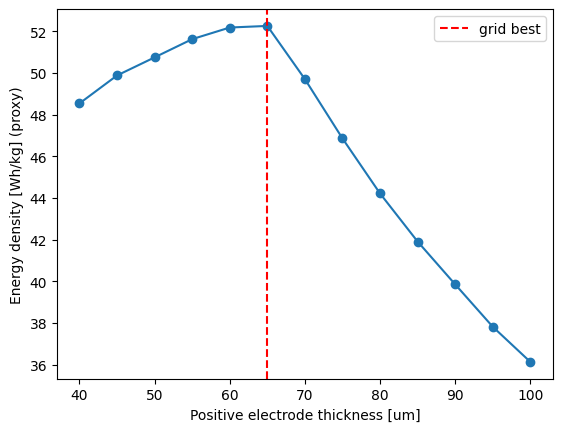

Grid-search best: 65.0 um -> 52.257 Wh/kg


In [21]:
def energy_density_wh_per_kg(thickness_m, mass_scale_kg_per_m=5000):
    params = pybamm.ParameterValues("Chen2020")
    params["Positive electrode thickness [m]"] = thickness_m
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 3600])
    t = sol["Time [s]"].data
    power_w = sol["Terminal voltage [V]"].data * sol["Current [A]"].data
    energy_wh = np.trapz(power_w, t) / 3600
    mass_kg = thickness_m * mass_scale_kg_per_m
    return energy_wh / mass_kg


thicknesses = np.linspace(40e-6, 100e-6, 13)
grid_results = pd.DataFrame(
    {"thickness_um": thicknesses * 1e6, "energy_density": [energy_density_wh_per_kg(x) for x in thicknesses]}
)
best_row = grid_results.loc[grid_results["energy_density"].idxmax()]

plt.figure()
plt.plot(grid_results["thickness_um"], grid_results["energy_density"], "o-")
plt.axvline(best_row["thickness_um"], color="red", linestyle="--", label="grid best")
plt.xlabel("Positive electrode thickness [um]")
plt.ylabel("Energy density [Wh/kg] (proxy)")
plt.legend()
plt.show()

print(f"Grid-search best: {best_row['thickness_um']:.1f} um -> {best_row['energy_density']:.3f} Wh/kg")

### Example 2: Refining with `scipy.optimize.minimize_scalar`

Grid search only ever finds a point *on the grid*. `minimize_scalar` with
`method="bounded"` uses golden-section search to converge on the true optimum within
a bounded interval — usually in far fewer model evaluations than a fine grid would
need. `scipy.optimize` only minimizes, so maximizing `energy_density_wh_per_kg` means
minimizing its negative.

In [33]:
result = minimize_scalar(
    lambda x: -energy_density_wh_per_kg(x),
    bounds=(40e-6, 100e-6),
    method="bounded",
    options={"xatol": 1e-7},
)

print(f"scipy-optimized best: {result.x * 1e6:.3f} um -> {-result.fun:.3f} Wh/kg")
print(f"Number of model evaluations: {result.nfev}")

scipy-optimized best: 64.918 um -> 52.257 Wh/kg
Number of model evaluations: 15


### Example 3: Putting it together — a `CellDesignOptimizer` class

The final step wraps the objective, a capacity *constraint*, and a cache into one
class — an OOP capstone that reuses the memoization pattern from Section 3 and the
optimization pattern from Example 2 above, applied to a design decision an engineer
actually cares about.

In [24]:
class CellDesignOptimizer:
    """Finds the positive electrode thickness maximising energy density subject to
    a minimum discharge capacity."""

    def __init__(self, min_capacity_ah, mass_scale_kg_per_m=5000):
        self.min_capacity_ah = min_capacity_ah
        self.mass_scale_kg_per_m = mass_scale_kg_per_m
        self._cache = {}

    def _simulate(self, thickness_m):
        if thickness_m not in self._cache:
            params = pybamm.ParameterValues("Chen2020")
            params["Positive electrode thickness [m]"] = thickness_m
            sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
            self._cache[thickness_m] = sim.solve([0, 3600])
        return self._cache[thickness_m]

    def objective(self, thickness_m):
        sol = self._simulate(thickness_m)
        t = sol["Time [s]"].data
        power_w = sol["Terminal voltage [V]"].data * sol["Current [A]"].data
        energy_wh = np.trapz(power_w, t) / 3600
        mass_kg = thickness_m * self.mass_scale_kg_per_m
        energy_density = energy_wh / mass_kg

        capacity_ah = sol["Discharge capacity [A.h]"].data[-1]
        if capacity_ah < self.min_capacity_ah:
            energy_density -= 1000 * (self.min_capacity_ah - capacity_ah)
        return energy_density

    def optimize(self, bounds=(40e-6, 100e-6)):
        result = minimize_scalar(lambda x: -self.objective(x), bounds=bounds, method="bounded")
        return result.x


optimizer = CellDesignOptimizer(min_capacity_ah=4.9)
best_thickness = optimizer.optimize()
print(f"Constrained optimum: {best_thickness * 1e6:.3f} um")
print(f"Unique simulations run (thanks to caching): {len(optimizer._cache)}")

Constrained optimum: 66.278 um
Unique simulations run (thanks to caching): 6


## 7. PyBaMM Command Cheat Sheet

A fast reference map of the PyBaMM API surface used throughout this notebook (and
beyond) — organised by task rather than by tutorial flow. Come back to this section
whenever you've forgotten a command name; it isn't meant to be read top-to-bottom.

### Example 1: Models — discovering and configuring them

Submodel options (thermal, SEI, particle mechanics, ...) are passed as a dict when the
model is constructed. Every model can tell you what it can report, how finely it's
meshed by default, and which parameter set it ships with.

In [34]:
# The main lithium-ion models, roughly fastest -> most detailed
pybamm.lithium_ion.SPM()     # Single Particle Model
pybamm.lithium_ion.SPMe()    # SPM with electrolyte effects
pybamm.lithium_ion.DFN()     # Doyle-Fuller-Newman (full porous-electrode theory)
pybamm.lithium_ion.MPM()     # Many-Particle Model (particle-size distribution)
pybamm.equivalent_circuit.Thevenin()  # ECM, for when you don't need electrochemistry

# Submodel options are passed as a dict at construction time
model = pybamm.lithium_ion.SPM({"thermal": "lumped"})
print("thermal option:", model.options["thermal"])

# Discover what a model can report and how it's configured
print("sample variables:", list(model.variables.keys())[:])
print("default mesh points:", model.default_var_pts)
print("ships with capacity:", model.default_parameter_values["Nominal cell capacity [A.h]"], "Ah")

thermal option: lumped
sample variables: ['Time [s]', 'Time [min]', 'Time [h]', 'x [m]', 'x_n [m]', 'x_s [m]', 'x_p [m]', 'r_n [m]', 'r_p [m]', 'Current variable [A]', 'Total current density [A.m-2]', 'Current [A]', 'C-rate', 'Discharge capacity [A.h]', 'Throughput capacity [A.h]', 'Discharge energy [W.h]', 'Throughput energy [W.h]', 'Porosity', 'Negative electrode porosity', 'X-averaged negative electrode porosity', 'Separator porosity', 'X-averaged separator porosity', 'Positive electrode porosity', 'X-averaged positive electrode porosity', 'Porosity change', 'Negative electrode porosity change [s-1]', 'X-averaged negative electrode porosity change [s-1]', 'Separator porosity change [s-1]', 'X-averaged separator porosity change [s-1]', 'Positive electrode porosity change [s-1]', 'X-averaged positive electrode porosity change [s-1]', 'Negative electrode interface utilisation variable', 'X-averaged negative electrode interface utilisation variable', 'Negative electrode interface utilis

### Example 2: Parameter values — listing, searching, overriding

`ParameterValues` behaves like a dict once you know the exact key string — `.search()`
is how you find that string without memorising it.

In [38]:
# List every built-in parameter set PyBaMM ships with
print(list(pybamm.parameter_sets)[:5], "...")

params = pybamm.ParameterValues("Chen2020")

# Search for parameter names you half-remember
params.search("diffusivity")

# Read / write like a dict
print(f"cell capacity is {params["Nominal cell capacity [A.h]"]}")
params["Ambient temperature [K]"] = 278.15
params.update({"Positive electrode thickness [m]": 8e-5})

# A Simulation keeps its own copy -- inspect what it's actually using
sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
print("sim is using ambient T =", sim.parameter_values["Ambient temperature [K]"], "K")

['Ai2020', 'Chayambuka2022', 'Chen2020', 'Chen2020_composite', 'ECM_Example'] ...
Results for 'diffusivity': ['SEI solvent diffusivity [m2.s-1]', 'SEI lithium interstitial diffusivity [m2.s-1]', 'EC diffusivity [m2.s-1]', 'Negative particle diffusivity [m2.s-1]', 'Positive particle diffusivity [m2.s-1]', 'Electrolyte diffusivity [m2.s-1]']
SEI solvent diffusivity [m2.s-1] -> 2.5e-22
SEI lithium interstitial diffusivity [m2.s-1] -> 1e-20
EC diffusivity [m2.s-1] -> 2e-18
Negative particle diffusivity [m2.s-1] -> 3.3e-14
Positive particle diffusivity [m2.s-1] -> 4e-15
Electrolyte diffusivity [m2.s-1] -> <function electrolyte_diffusivity_Nyman2008 at 0x000001E65B573420>
cell capacity is 5.0
sim is using ambient T = 278.15 K


### Example 3: Simulation and Experiment — the two ways to drive a model

Use a plain time window when you just want the model's default (usually constant)
current. Use an `Experiment` when you need a sequence of realistic operating
steps — it defines its own time window, so you call `sim.solve()` with no arguments.

{'Ambient temperature [K]': 298.15,
 'Bulk solvent concentration [mol.m-3]': 2636.0,
 'Cation transference number': 0.4,
 'Cell cooling surface area [m2]': 0.0569,
 'Cell volume [m3]': 7.8e-06,
 'Contact resistance [Ohm]': 0,
 'Current function [A]': 0.680616,
 'EC diffusivity [m2.s-1]': 2e-18,
 'EC initial concentration in electrolyte [mol.m-3]': 4541.0,
 'Edge heat transfer coefficient [W.m-2.K-1]': 0.3,
 'Electrode height [m]': 0.137,
 'Electrode width [m]': 0.207,
 'Electrolyte conductivity [S.m-1]': <function electrolyte_conductivity_Capiglia1999 at 0x000001E65CE42F20>,
 'Electrolyte diffusivity [m2.s-1]': <function electrolyte_diffusivity_Capiglia1999 at 0x000001E65CE42CA0>,
 'Initial SEI thickness [m]': 5e-09,
 'Initial concentration in electrolyte [mol.m-3]': 1000.0,
 'Initial concentration in negative electrode [mol.m-3]': 19986.609595075,
 'Initial concentration in positive electrode [mol.m-3]': 30730.7554385565,
 'Initial temperature [K]': 298.15,
 'Lithium interstitial refe

interactive(children=(FloatSlider(value=0.0, description='t', max=1.0, step=0.01), Output()), _dom_classes=('w…

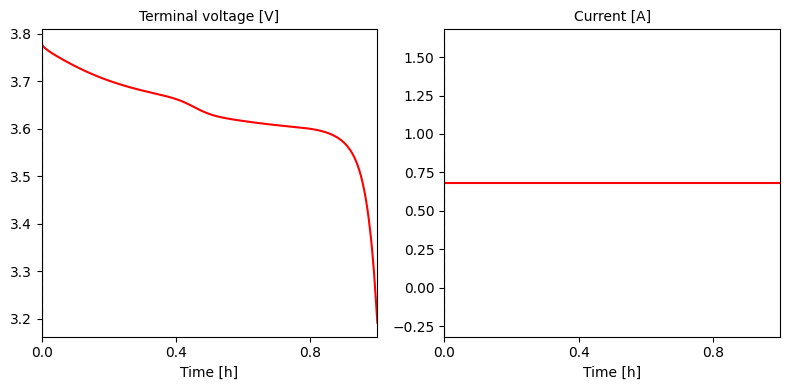

In [78]:
model = pybamm.lithium_ion.SPM()
# params.search("current")
print(model.default_parameter_values)
# params.update({"Current function [A]": 2})

# 1) a plain time window -- uses the model's default current
sim = pybamm.Simulation(model)
sim.parameter_values.search("current")
sol = sim.solve([0, 3600])                         # solve from 0 to 3600 s
sol = sim.solve(t_eval=np.linspace(0, 3600, 50))   # or a full array of evaluation points

sim.plot(["Terminal voltage [V]", "Current [A]"])
# 2) an Experiment -- a sequence of human-readable operating steps
# experiment = pybamm.Experiment(
#     ["Discharge at 2A until 3.0 V", "Rest for 10 minutes", "Charge at 0.5C until 4.2 V"]
# )
# sim = pybamm.Simulation(model, experiment=experiment, parameter_values=params)
# sol = sim.solve()  # no time window needed -- the experiment defines it

# sim.plot(["Terminal voltage [V]", "Current [A]"])

### Example 4: Solvers — choosing and configuring one

`CasadiSolver(mode="safe")` is the default: robust, with full event-checking.
`mode="fast"` skips some of that checking for speed. `IDAKLUSolver` is often the
fastest choice for stiffer, DFN-sized models.

In [ ]:
model = pybamm.lithium_ion.SPM()

sim_fast = pybamm.Simulation(model, solver=pybamm.CasadiSolver(mode="fast"))
sim_idaklu = pybamm.Simulation(model, solver=pybamm.IDAKLUSolver())

for sim in (sim_fast, sim_idaklu):
    sol = sim.solve([0, 600])
    print(type(sim.solver).__name__, "->", sol["Terminal voltage [V]"].data[-1])

### Example 5: Solution, post-processing, saving and loading

1D-in-time variables expose `.data`; variables with spatial structure expose
`.entries`. A `Solution` can be pickled to disk with `.save()` and restored later with
`pybamm.load()`, without re-solving.

reloaded V_end = 3.1915673887366403


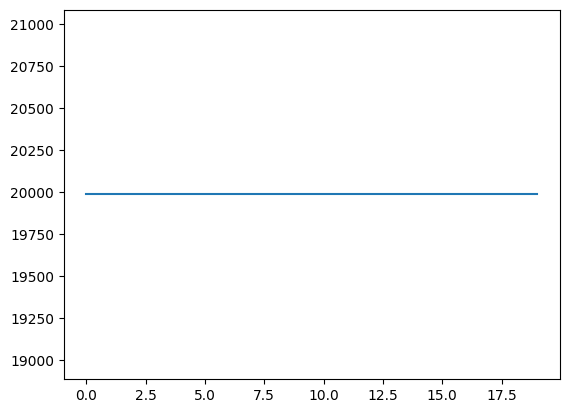

<Figure size 640x480 with 0 Axes>

In [69]:
sol = pybamm.Simulation(pybamm.lithium_ion.SPM()).solve([0, 3600])

# 1D variables: .data ; spatially-resolved variables: .entries
voltage = sol["Terminal voltage [V]"].data
particle_surface_c = sol["Negative particle surface concentration [mol.m-3]"].entries

# Multi-cycle experiments split into sol.cycles[0], sol.cycles[1], ...
# and sol.summary_variables -- see Section 8, Example 6.
# sol.plot(["Negative particle surface concentration [mol.m-3]"])
plt.plot(particle_surface_c[:, 0])  # first and last cycles

plt.figure()

# Persist a solution and reload it later without re-solving
sol.save("my_solution.pkl")
reloaded = pybamm.load("my_solution.pkl")
print("reloaded V_end =", reloaded["Terminal voltage [V]"].data[-1])

import os
os.remove("my_solution.pkl")

## 8. Real-World Design Workflows (Use Cases)

Six workflows an engineer actually reaches for day to day, each combining tools from
earlier sections: comparing a simulation against bench data, fitting a parameter to
match that data, representing the resulting uncertainty, running a sensitivity study,
simulating a real duty cycle, and the bookkeeping behind a multi-cycle ageing study.

### Example 1: Overlaying a simulation against reference data

The most basic comparison workflow: plot both curves together, then resample the
simulation onto the reference's time points (Section 4) to get a single error number.

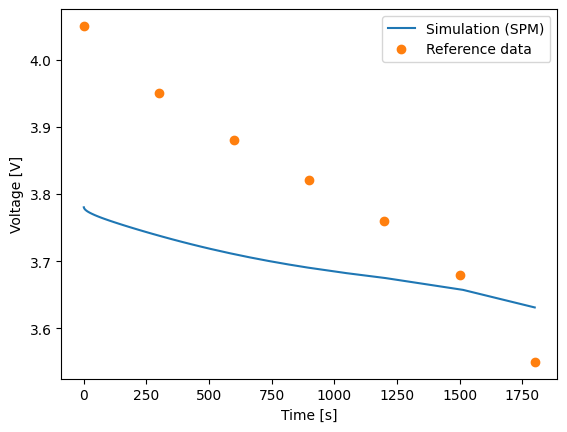

RMSE vs reference: 159.4 mV


In [74]:
# Synthetic "measured" reference data standing in for a real bench-test export
reference_t = np.array([0, 300, 600, 900, 1200, 1500, 1800])
reference_v = np.array([4.05, 3.95, 3.88, 3.82, 3.76, 3.68, 3.55])

sol = pybamm.Simulation(pybamm.lithium_ion.SPM()).solve([0, 1800])

plt.figure()
plt.plot(sol["Time [s]"].data, sol["Terminal voltage [V]"].data, label="Simulation (SPM)")
plt.plot(reference_t, reference_v, "o", label="Reference data")
plt.xlabel("Time [s]")
plt.ylabel("Voltage [V]")
plt.legend()
plt.show()

v_sim_at_ref_t = np.interp(reference_t, sol["Time [s]"].data, sol["Terminal voltage [V]"].data)
rmse = np.sqrt(np.mean((v_sim_at_ref_t - reference_v) ** 2))
print(f"RMSE vs reference: {rmse * 1000:.1f} mV")

### Example 2: Fitting a model parameter to reference data

Same idea as Section 6's optimizer, aimed at a calibration problem instead of a design
one: find the parameter value that makes the model best match measured data. Here we
fit the series resistance `R0` of an equivalent circuit model to a synthetic pulse-test
reference — a clean, strongly identifiable single-parameter fit.

For anything beyond this (several parameters at once, uncertainty quantification,
fitting across many models) reach for **PyBOP** (`pybop-team/PyBOP`) — it builds on
exactly this idea with purpose-built optimisers and samplers.

In [79]:
ecm = pybamm.equivalent_circuit.Thevenin()
ecm_base_params = ecm.default_parameter_values


def run_ecm(r0_ohm, current_a=5.0, t_end=600):
    params = pybamm.ParameterValues(ecm_base_params)
    params["R0 [Ohm]"] = r0_ohm
    params["Current function [A]"] = current_a
    sim = pybamm.Simulation(ecm, parameter_values=params)
    return sim.solve([0, t_end])


# Pretend this came from a pulse test on the bench (true R0 = 0.025 ohm)
t_common = np.linspace(0, 600, 60)
sol_reference = run_ecm(r0_ohm=0.025)
v_reference = np.interp(
    t_common, sol_reference["Time [s]"].data, sol_reference["Battery voltage [V]"].data
)


def fit_error(r0_ohm):
    sol = run_ecm(r0_ohm)
    v = np.interp(t_common, sol["Time [s]"].data, sol["Battery voltage [V]"].data)
    return np.sqrt(np.mean((v - v_reference) ** 2))


result = minimize_scalar(fit_error, bounds=(0.005, 0.05), method="bounded")
print(f"Fitted R0 = {result.x:.5f} ohm (true value was 0.025 ohm)")

Fitted R0 = 0.02500 ohm (true value was 0.025 ohm)


### Example 3: Representing simulation uncertainty with an error band

If `R0` is only known to within +/-20% (manufacturing spread, ageing, measurement
error, ...), running the low and high cases and shading between them with
`plt.fill_between` turns that uncertainty into a visual error band around the nominal
prediction — reusing `run_ecm` from Example 2.

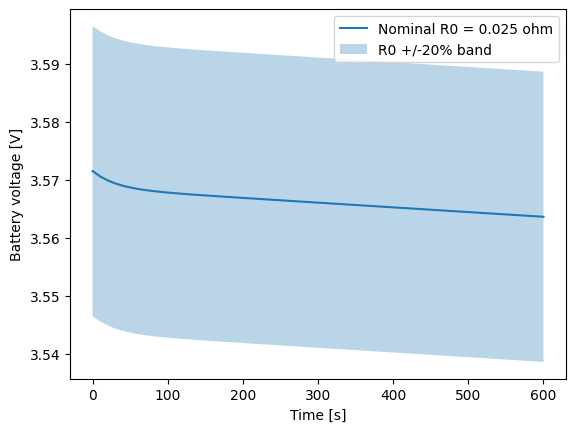

In [80]:
nominal_r0 = 0.025
sol_nom = run_ecm(nominal_r0)
sol_lo = run_ecm(nominal_r0 * 0.8)
sol_hi = run_ecm(nominal_r0 * 1.2)

v_nom = np.interp(t_common, sol_nom["Time [s]"].data, sol_nom["Battery voltage [V]"].data)
v_lo = np.interp(t_common, sol_lo["Time [s]"].data, sol_lo["Battery voltage [V]"].data)
v_hi = np.interp(t_common, sol_hi["Time [s]"].data, sol_hi["Battery voltage [V]"].data)

plt.figure()
plt.plot(t_common, v_nom, label="Nominal R0 = 0.025 ohm")
plt.fill_between(t_common, v_lo, v_hi, alpha=0.3, label="R0 +/-20% band")
plt.xlabel("Time [s]")
plt.ylabel("Battery voltage [V]")
plt.legend()
plt.show()

### Example 4: One-at-a-time sensitivity analysis

Perturb each design parameter by the same +10% in turn, re-run, and record the %
change in an output metric — the classic one-at-a-time (OAT) local sensitivity sweep.
Collecting the results into a DataFrame (Section 5) and plotting a horizontal bar chart
gives a quick "tornado chart" of which parameters actually matter for this metric.

{}
7.56e-05
{'Positive electrode thickness [m]': 8.316e-05}
8.52e-05
{'Negative electrode thickness [m]': 9.372e-05}
0.665
{'Positive electrode active material volume fraction': 0.7315000000000002}
0.75
{'Negative electrode active material volume fraction': 0.8250000000000001}
5.22e-06
{'Positive particle radius [m]': 5.742e-06}
5.86e-06
{'Negative particle radius [m]': 6.446000000000001e-06}


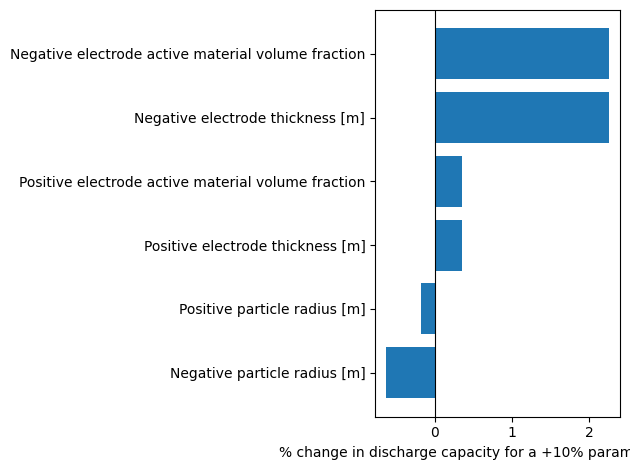

,parameter,pct_change_for_plus10pct
5,Negative particle radius [m],-0.627352
4,Positive particle radius [m],-0.183130
0,Positive electrode thickness [m],0.356139
2,Positive electrode active material volume frac...,0.356139
1,Negative electrode thickness [m],2.252245
3,Negative electrode active material volume frac...,2.252245


In [83]:
params0 = pybamm.ParameterValues("Chen2020")
nominal_capacity = params0["Nominal cell capacity [A.h]"]


def discharge_capacity(overrides, c_rate=1.5):
    params = pybamm.ParameterValues("Chen2020")
    print(overrides)
    params.update(overrides)
    params["Current function [A]"] = nominal_capacity * c_rate
    sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
    sol = sim.solve([0, 3600 / c_rate])
    return sol["Discharge capacity [A.h]"].data[-1]


base_capacity = discharge_capacity({})

sensitivity_params = [
    "Positive electrode thickness [m]",
    "Negative electrode thickness [m]",
    "Positive electrode active material volume fraction",
    "Negative electrode active material volume fraction",
    "Positive particle radius [m]",
    "Negative particle radius [m]",
]

rows = []
for name in sensitivity_params:
    nominal_value = params0[name]
    print(nominal_value)
    perturbed_capacity = discharge_capacity({name: nominal_value * 1.1})
    pct_change = 100 * (perturbed_capacity - base_capacity) / base_capacity
    rows.append({"parameter": name, "pct_change_for_plus10pct": pct_change})

sensitivity_df = pd.DataFrame(rows).sort_values("pct_change_for_plus10pct")

plt.figure()
plt.barh(sensitivity_df["parameter"], sensitivity_df["pct_change_for_plus10pct"])
plt.xlabel("% change in discharge capacity for a +10% parameter change")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
sensitivity_df

### Example 5: Simulating a real duty/drive cycle

Real current profiles (a drive cycle, a pulse-test schedule, a logged duty cycle)
rarely fit a one-line formula. `pybamm.Interpolant(t_data, i_data, pybamm.t)` turns a
plain `(t, I)` data series into a PyBaMM-compatible current function — the same
mechanism PyBaMM's own `examples/scripts/drive_cycle.py` uses for the US06 cycle.

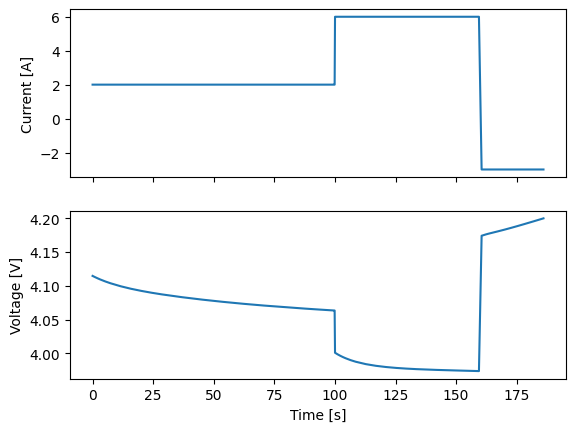

In [84]:
# A synthetic duty cycle: discharge, a sharp power pulse, a short regen (charge) pulse, discharge
drive_t = np.array([0, 100, 100, 160, 160, 220, 220, 400])
drive_i = np.array([2.0, 2.0, 6.0, 6.0, -3.0, -3.0, 2.0, 2.0])  # A; positive = discharge

params = pybamm.ParameterValues("Chen2020")
params["Current function [A]"] = pybamm.Interpolant(drive_t, drive_i, pybamm.t)
sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), parameter_values=params)
sol = sim.solve([0, 400])

fig, axes = plt.subplots(2, 1, sharex=True)
axes[0].plot(sol["Time [s]"].data, sol["Current [A]"].data)
axes[0].set_ylabel("Current [A]")
axes[1].plot(sol["Time [s]"].data, sol["Terminal voltage [V]"].data)
axes[1].set_ylabel("Voltage [V]")
axes[1].set_xlabel("Time [s]")
plt.show()

### Example 6: Multi-cycle summary variables for an ageing study

An `Experiment` repeated over many cycles exposes `solution.summary_variables` — one
row of headline numbers (capacity, lithium inventory, SEI losses, ...) per cycle,
without having to re-process the full time-resolved solution. This is the bookkeeping
layer underneath a real capacity-fade study.

Plain SPM with no degradation submodel enabled (the default here) won't show much
fade over just 5 cycles — the point is the extraction mechanics. To see genuine fade,
enable options such as `{"SEI": "ec reaction limited"}`, the way your own
`pybamm_sei_fade.py` script does with SPMe.

In [85]:
experiment = pybamm.Experiment(
    [("Discharge at 1C until 3.0 V", "Charge at 0.5C until 4.2 V")] * 5
)
sim = pybamm.Simulation(pybamm.lithium_ion.SPM(), experiment=experiment)
sol = sim.solve()

summary = sol.summary_variables
fade_df = pd.DataFrame(
    {"cycle": summary.cycle_number, "capacity_ah": summary["Capacity [A.h]"]}
)
fade_df

,cycle,capacity_ah
0,1,0.87284
1,2,0.87284
2,3,0.87284
3,4,0.87284
4,5,0.87284


## Conclusion

This notebook walked through eight areas, each grounded in a battery-engineering
task and, from Section 2 onward, real PyBaMM simulations:

1. **Object-oriented design** — validated properties, inheritance/polymorphism for
   composable circuit models, and `@dataclass` as a bridge to `pybamm.ParameterValues`.
2. **Functional programming** — functions as first-class objects, closures for
   parameterised PyBaMM parameter functions, and `functools.partial` for building
   families of profile functions.
3. **Iterators, generators, decorators and context managers** — lazily generating
   cycling protocols and sweep grids, timing/caching simulations with decorators, and
   `@contextmanager` for clean "wrap this block" logic.
4. **NumPy vectorization** — `np.trapezoid` for capacity integration, `np.gradient`
   for incremental capacity analysis, and `np.interp` for comparing curves on a common
   grid.
5. **pandas for tidy data** — building sweep results directly into DataFrames, then
   `groupby`/`pivot`/`merge` to summarise and compare against reference data.
6. **Optimization** — grid search vs. `scipy.optimize.minimize_scalar`, and a capstone
   `CellDesignOptimizer` class combining a cache, an objective and a constraint into a
   reusable design-space exploration tool.
7. **PyBaMM command cheat sheet** — a task-organised reference for models, parameter
   values, Simulation/Experiment, solvers, and solution post-processing/saving.
8. **Real-world design workflows** — overlaying simulation against reference data,
   fitting a parameter to match it, representing uncertainty with an error band,
   one-at-a-time sensitivity analysis, simulating a real duty cycle, and the
   multi-cycle bookkeeping behind an ageing study.

The companion **Exercises** notebook has 3 hands-on problems per section for Sections
1-6 (18 total) — each test cell already shows the target output from a working
reference solution, so you can check your implementation as you go. Sections 7-8 are
reference/demonstration material and don't (yet) have matching exercises. The
**Solutions** notebook has every problem fully worked and executed.

### Further reading
- [PyBaMM documentation home](https://docs.pybamm.org/)
- [PyBaMM: Simulation class reference](https://docs.pybamm.org/en/latest/source/api/simulation.html)
- [PyBaMM: ParameterValues reference](https://docs.pybamm.org/en/latest/source/api/parameters/parameter_values.html)
- [PyBaMM: Experiment reference](https://docs.pybamm.org/en/latest/source/api/experiment/experiment.html)
- [PyBaMM example notebooks index](https://docs.pybamm.org/en/latest/source/examples/index.html)
- [Python: dataclasses](https://docs.python.org/3/library/dataclasses.html)
- [Python: itertools](https://docs.python.org/3/library/itertools.html)
- [Python: functools](https://docs.python.org/3/library/functools.html)
- [Python: contextlib](https://docs.python.org/3/library/contextlib.html)
- [NumPy user guide](https://numpy.org/doc/stable/user/index.html)
- [pandas user guide](https://pandas.pydata.org/docs/user_guide/index.html)
- [SciPy optimize reference](https://docs.scipy.org/doc/scipy/reference/optimize.html)
- [PyBOP (parameter estimation / optimisation for PyBaMM)](https://github.com/pybop-team/PyBOP)